# Regression Analysis (A): Uber Fare Prediction
Predict the fare of an Uber ride using Linear, Ridge and Lasso regression on the Kaggle *Uber Fares Dataset*.

## 1. Load and Explore the Dataset
The dataset is downloaded directly from Kaggle using `kagglehub` (run the install cell once; Kaggle may ask you to log in).

In [1]:
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

plt.style.use("seaborn-v0_8-whitegrid")

path = kagglehub.dataset_download("yasserh/uber-fares-dataset")
df = pd.read_csv(os.path.join(path, "uber.csv"))
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum()[lambda s: s > 0])
df.head()

Shape: (200000, 9)
Missing values:
 dropoff_longitude    1
dropoff_latitude     1
dtype: int64


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
df.describe().round(2)

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,200000.00,200000.00,200000.00,200000.00,199999.00,199999.00,200000.00
mean,27712503.68,11.36,-72.53,39.94,-72.53,39.92,1.68
std,16013822.21,9.90,11.44,7.72,13.12,6.79,1.39
min,1.00,-52.00,-1340.65,-74.02,-3356.67,-881.99,0.00
25%,13825346.25,6.00,-73.99,40.73,-73.99,40.73,1.00
50%,27745495.00,8.50,-73.98,40.75,-73.98,40.75,1.00
75%,41555300.75,12.50,-73.97,40.77,-73.96,40.77,2.00
max,55423567.00,499.00,57.42,1644.42,1153.57,872.70,208.00


## 2. Pre-process the Dataset
Drop unused columns and missing rows, extract time features from the pickup time, compute the trip distance (haversine formula) and remove invalid records.

In [4]:
df = df.drop(columns=[c for c in ["Unnamed: 0", "key"] if c in df.columns]).dropna().drop_duplicates()

# Time features
t = pd.to_datetime(df["pickup_datetime"])
df["hour"], df["dayofweek"], df["month"], df["year"] = t.dt.hour, t.dt.dayofweek, t.dt.month, t.dt.year

# Trip distance in km (haversine)
lat1, lon1, lat2, lon2 = map(np.radians, [df.pickup_latitude, df.pickup_longitude, df.dropoff_latitude, df.dropoff_longitude])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

# Remove invalid records
valid = (
    (df.fare_amount > 0) & df.passenger_count.between(1, 6) & (df.distance_km > 0)
    & df.pickup_latitude.between(-90, 90) & df.dropoff_latitude.between(-90, 90)
    & df.pickup_longitude.between(-180, 180) & df.dropoff_longitude.between(-180, 180)
)
df = df[valid].drop(columns="pickup_datetime")
print("Records after cleaning:", len(df))

Records after cleaning: 193644


## 3. Identify and Remove Outliers (IQR method)

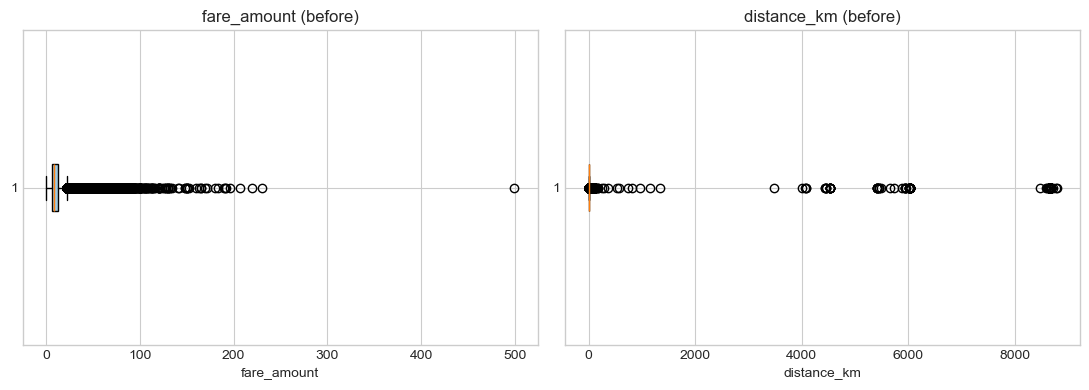

Outliers removed: 24625  |  Records remaining: 169019


In [5]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, col in zip(ax, ["fare_amount", "distance_km"]):
    a_.boxplot(df[col], vert=False, patch_artist=True, boxprops={"facecolor": "#9ecae1"})
    a_.set(title=f"{col} (before)", xlabel=col)
plt.tight_layout()
plt.show()

n_before = len(df)
for col in ["fare_amount", "distance_km"]:
    lo, hi = iqr_bounds(df[col])
    df = df[df[col].between(lo, hi)]
print(f"Outliers removed: {n_before - len(df)}  |  Records remaining: {len(df)}")

## 4. Check the Correlation

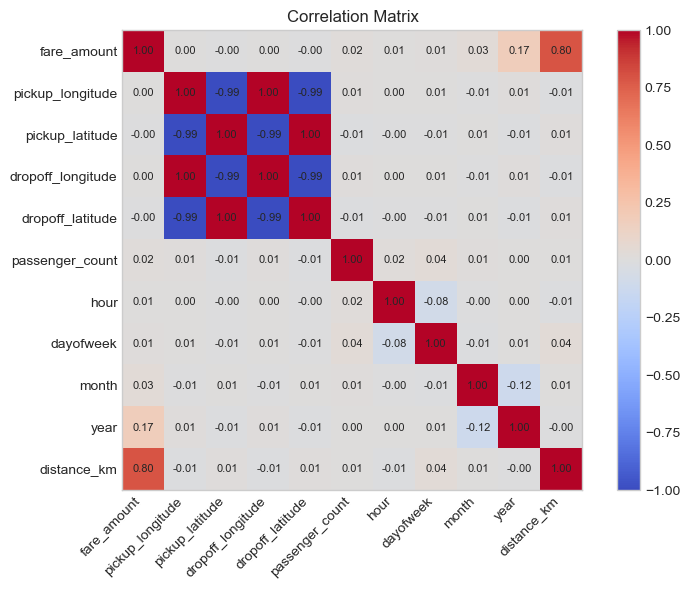

Correlation with fare_amount:
 distance_km          0.796
year                 0.173
month                0.033
passenger_count      0.017
dayofweek            0.013
hour                 0.007
dropoff_longitude    0.003
pickup_longitude     0.002
pickup_latitude     -0.003
dropoff_latitude    -0.004
Name: fare_amount, dtype: float64


In [6]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

print("Correlation with fare_amount:\n", corr["fare_amount"].drop("fare_amount").sort_values(ascending=False).round(3))

## 5. Implement Linear, Ridge and Lasso Regression

In [7]:
X, y = df.drop(columns="fare_amount"), df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear":         LinearRegression(),
    "Ridge (a=1)":    Ridge(alpha=1),
    "Lasso (a=0.01)": Lasso(alpha=0.01),
}

results = {}
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results[name] = {
        "R2 (train)": pipe.score(X_train, y_train),
        "R2 (test)": r2_score(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
    }
    models[name] = (pipe, pred)

results = pd.DataFrame(results).T
results.round(4)

,R2 (train),R2 (test),RMSE,MAE
Linear,0.6677,0.6730,2.1269,1.5198
Ridge (a=1),0.6676,0.6729,2.1271,1.5198
Lasso (a=0.01),0.6656,0.6710,2.1334,1.5250


## 6. Compare the Models

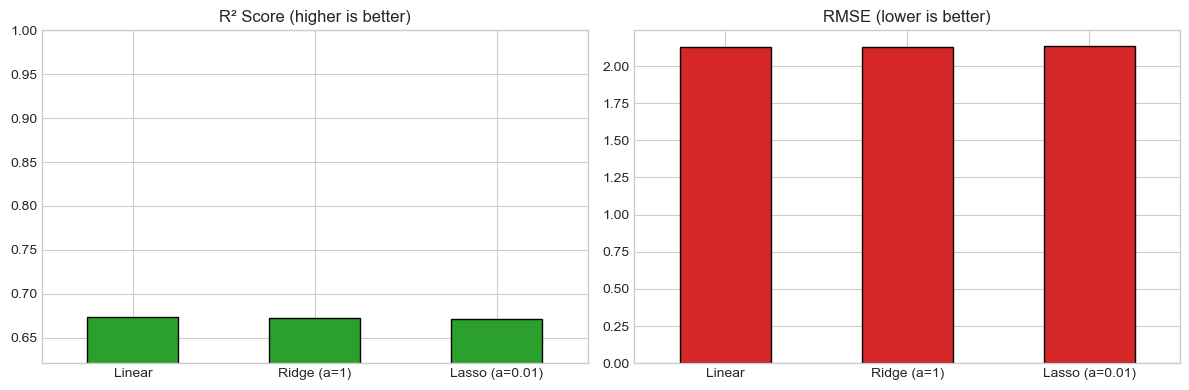

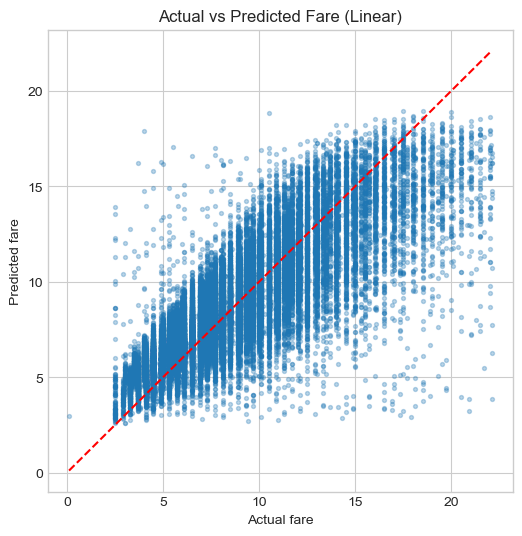

Lasso coefficients (zero = feature dropped):
pickup_longitude     0.029
pickup_latitude     -0.000
dropoff_longitude    0.000
dropoff_latitude    -0.000
passenger_count      0.034
hour                 0.046
dayofweek           -0.054
month                0.169
year                 0.665
distance_km          2.955


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
results["R2 (test)"].plot(kind="bar", ax=ax[0], color="#2ca02c", edgecolor="black", rot=0)
ax[0].set(title="R² Score (higher is better)", ylim=(results["R2 (test)"].min() - 0.05, 1))
results["RMSE"].plot(kind="bar", ax=ax[1], color="#d62728", edgecolor="black", rot=0)
ax[1].set(title="RMSE (lower is better)")
plt.tight_layout()
plt.show()

best = results["R2 (test)"].idxmax()
plt.figure(figsize=(6, 6))
plt.scatter(y_test, models[best][1], alpha=0.3, s=8)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title(f"Actual vs Predicted Fare ({best})")
plt.xlabel("Actual fare"); plt.ylabel("Predicted fare")
plt.show()

print("Lasso coefficients (zero = feature dropped):")
print(pd.Series(models["Lasso (a=0.01)"][0][-1].coef_, index=X.columns).round(3).to_string())

## 7. Conclusion
- Trip distance has by far the strongest correlation with the fare; the other features are only weakly correlated.
- Linear, Ridge and Lasso give almost identical scores, because the number of features is small and there is little overfitting, so regularization has little to correct.
- The R² and RMSE table shows which model is best; if the differences are small, the simplest model (Linear) is a reasonable choice.
- Remaining error is due to factors not in the data, such as traffic, tolls and surge pricing.